# RHG DMRG validation notebook, corrected production version

This notebook implements the DMRG validation layer for the rhombohedral-graphene thermal-Hall project.
The many-body calculation is not meant to reproduce the full continuum band structure of RHG.  It is the controlled lattice validator used in the draft: a spinless chiral $p+ip$ BdG superconductor on a finite cylinder, with $C_{\rm BdG}=1$, $\mathbb Z_2$ fermion-parity conservation, and exponential finite-width corrections.

The notebook produces, for every completed $(L_x,L_y,\Delta_{\rm pg})$ case:

1. a master CSV summary,
2. a pickle archive with observables, spectra, profiles, parameters, and DMRG sweep history,
3. a TeNPy/HDF5 MPS checkpoint for post-hoc observables,
4. diagnostic figures.

The default `RUN_MODE="quick"` is intentionally small.  Change to `production` or `draft_protocol` for the paper-scale runs.

## Installation

Run this once in the environment where the notebook will be executed:

```bash
pip install physics-tenpy h5py scipy pandas matplotlib
```

For reproducibility, keep the generated output directory together with this notebook.  The HDF5 files contain the MPS checkpoint and JSON metadata needed to reconstruct the model parameters.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "DejaVu Serif", "Times New Roman"],
    "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 14,
    "axes.titlesize": 13,
    "legend.fontsize": 10,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

OUTDIR = Path("RHG_BdG_corrected_figures")
OUTDIR.mkdir(exist_ok=True)
print("Output directory:", OUTDIR.resolve())

Output directory: /home/kumar/Desktop/DMRG_RHG/RHG_BdG_corrected_figures


In [2]:
import sys, os, json, pickle, time, platform, warnings, logging, math
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import h5py
    HAS_H5PY = True
except Exception as exc:
    h5py = None
    HAS_H5PY = False
    warnings.warn(f"h5py import failed: {exc}. HDF5 MPS export will be disabled.")

try:
    import tenpy
    from tenpy.models.model import CouplingMPOModel
    from tenpy.networks.site import FermionSite
    from tenpy.networks.mps import MPS
    from tenpy.algorithms import dmrg
    from tenpy.tools import hdf5_io
    HAS_TENPY = True
except Exception as exc:
    tenpy = None
    CouplingMPOModel = object
    FermionSite = None
    MPS = None
    dmrg = None
    hdf5_io = None
    HAS_TENPY = False
    TENPY_IMPORT_ERROR = exc
    warnings.warn("TeNPy is not installed. Exact BdG checks will run, but DMRG cells require physics-tenpy.")

if HAS_TENPY:
    try:
        tenpy.setup_logging(to_stdout="INFO")
    except Exception:
        logging.basicConfig(level=logging.INFO)

print(f"Python:   {sys.version.split()[0]}")
print(f"Platform: {platform.platform()}")
print(f"NumPy:    {np.__version__}")
print(f"pandas:   {pd.__version__}")
print(f"h5py:     {h5py.__version__ if HAS_H5PY else 'not available'}")
print(f"TeNPy:    {getattr(tenpy, '__version__', 'not available') if HAS_TENPY else 'not available'}")

Python:   3.11.15
Platform: Linux-6.8.0-134-generic-x86_64-with-glibc2.39
NumPy:    2.4.4
pandas:   2.3.3
h5py:     3.16.0
TeNPy:    1.1.0


In [3]:
# =============================================================================
# Run configuration
# =============================================================================
# quick          : minimal smoke test, small enough for debugging.
# pilot          : one circumference, full Delta scan.
# production     : Ly=4,6,8, Delta=0.2,...,0.8.
# draft_protocol : draft proposal Lx=8, Ly=4,6,8,10, chi ramp up to 512.
# =============================================================================

RUN_MODE = "draft_protocol"       # change to "production" or "draft_protocol" for paper runs
RUN_DMRG = HAS_TENPY     # if TeNPy is missing, exact checks run and DMRG is skipped
FORCE_RERUN = False      # if False, completed rows in the CSV are skipped
SAVE_MPS = True          # save full MPS state to HDF5 when h5py and TeNPy HDF5 export are available

OUTDIR = Path("rhg_dmrg_validation_corrected")
OUTDIR.mkdir(exist_ok=True)
MPS_DIR = OUTDIR / "mps_hdf5"
PKL_DIR = OUTDIR / "archives_pickle"
FIG_DIR = OUTDIR / "figures"
for p in [MPS_DIR, PKL_DIR, FIG_DIR]:
    p.mkdir(exist_ok=True)

CONFIGS = {
    "quick": dict(
        Lx_values=[4], Ly_values=[4],
        Delta_values=[0.40],
        t=1.0, mu=1.0, V_nn=0.0, chirality=+1,
        chi_max=64, max_sweeps=8,
        chi_list={0: 16, 2: 32, 4: 64},
        Nk_chern=31,
    ),
    "pilot": dict(
        Lx_values=[8], Ly_values=[4],
        Delta_values=[0.20, 0.30, 0.40, 0.60, 0.80],
        t=1.0, mu=1.0, V_nn=0.0, chirality=+1,
        chi_max=256, max_sweeps=20,
        chi_list={0: 32, 3: 64, 6: 128, 10: 256},
        Nk_chern=41,
    ),
    "production": dict(
        Lx_values=[8], Ly_values=[4, 6, 8],
        Delta_values=[0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80],
        t=1.0, mu=1.0, V_nn=0.0, chirality=+1,
        chi_max=512, max_sweeps=25,
        chi_list={0: 64, 3: 128, 6: 256, 10: 512},
        Nk_chern=51,
    ),
    "draft_protocol": dict(
        Lx_values=[8], Ly_values=[4, 6, 8, 10],
        Delta_values=[0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80],
        t=1.0, mu=1.0, V_nn=0.0, chirality=+1,
        chi_max=512, max_sweeps=25,
        chi_list={0: 64, 3: 128, 6: 256, 10: 512},
        Nk_chern=51,
    ),
}

cfg = CONFIGS[RUN_MODE]
CSV_PATH = OUTDIR / "rhg_dmrg_validation_master.csv"
print(json.dumps(cfg, indent=2))
print(f"Output directory: {OUTDIR.resolve()}")

{
  "Lx_values": [
    8
  ],
  "Ly_values": [
    4,
    6,
    8,
    10
  ],
  "Delta_values": [
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8
  ],
  "t": 1.0,
  "mu": 1.0,
  "V_nn": 0.0,
  "chirality": 1,
  "chi_max": 512,
  "max_sweeps": 25,
  "chi_list": {
    "0": 64,
    "3": 128,
    "6": 256,
    "10": 512
  },
  "Nk_chern": 51
}
Output directory: /home/kumar/Desktop/DMRG_RHG/rhg_dmrg_validation_corrected


## 1. Exact BdG checks

The DMRG model is the real-space second-quantized version of

$$
H_{\rm BdG}(\mathbf{k}) =
\begin{pmatrix}
\xi_{\mathbf{k}} & \Delta(\sin k_x - i\chi\sin k_y)\\
\Delta(\sin k_x + i\chi\sin k_y) & -\xi_{\mathbf{k}}
\end{pmatrix},
\qquad
\xi_{\mathbf{k}}=2t(2-\cos k_x-\cos k_y)-\mu.
$$

For $0<\mu<4t$ and chirality $\chi=+1$, this convention gives $C_{\rm BdG}=+1$.
The real-space pair creation amplitudes are normalized so that the Bloch pairing is exactly the one above:

$$
A_{x}=-\frac{i\Delta}{2},\qquad A_y=-\frac{\chi\Delta}{2},
$$

with $A_{ij}=-A_{ji}$.  This fixes the common factor-of-two ambiguity between lattice pair amplitudes and the $\sin k$ BdG gap.

In [4]:
def h_bdg_k(kx, ky, *, t=1.0, mu=1.0, Delta=0.3, chirality=+1):
    """2x2 lattice p+ip BdG Hamiltonian used for the FHS Chern number."""
    dz = 2.0 * t * (2.0 - np.cos(kx) - np.cos(ky)) - mu
    off = Delta * np.sin(kx) - 1j * chirality * Delta * np.sin(ky)
    return np.array([[dz, off], [np.conj(off), -dz]], dtype=complex)


def fhs_chern_number(*, t=1.0, mu=1.0, Delta=0.3, chirality=+1, Nk=41):
    """Fukui-Hatsugai-Suzuki Chern number for the occupied BdG band."""
    vec = np.empty((Nk, Nk, 2), dtype=complex)
    for ix in range(Nk):
        kx = 2.0 * np.pi * ix / Nk - np.pi
        for iy in range(Nk):
            ky = 2.0 * np.pi * iy / Nk - np.pi
            w, v = np.linalg.eigh(h_bdg_k(kx, ky, t=t, mu=mu, Delta=Delta, chirality=chirality))
            vec[ix, iy] = v[:, np.argmin(w)]

    def link(u, v):
        z = np.vdot(u, v)
        if abs(z) < 1.0e-14:
            raise FloatingPointError("FHS link nearly singular; increase Nk or shift grid.")
        return z / abs(z)

    flux = 0.0
    max_plaquette_flux = 0.0
    for ix in range(Nk):
        for iy in range(Nk):
            u00 = vec[ix, iy]
            u10 = vec[(ix + 1) % Nk, iy]
            u01 = vec[ix, (iy + 1) % Nk]
            u11 = vec[(ix + 1) % Nk, (iy + 1) % Nk]
            Ux = link(u00, u10)
            Uy_x = link(u10, u11)
            Ux_y = link(u01, u11)
            Uy = link(u00, u01)
            plaquette = np.angle(Ux * Uy_x / (Ux_y * Uy))
            flux += plaquette
            max_plaquette_flux = max(max_plaquette_flux, abs(float(plaquette)))
    return dict(C=float(flux / (2.0 * np.pi)), max_plaquette_flux=max_plaquette_flux, Nk=Nk)


def pair_coefficients(Delta, chirality=+1):
    """Directed pair-creation amplitudes A_x, A_y for Cd_i Cd_j.

    With antisymmetric A_{ij}=-A_{ji}, these give the Bloch off-diagonal
    Delta*(sin kx - i*chirality*sin ky).
    """
    return (-0.5j * Delta, -0.5 * chirality * Delta)


def site_index(x, y, Ly):
    return x * Ly + (y % Ly)


def build_quadratic_matrices_cylinder(Lx, Ly, *, t=1.0, mu=1.0, Delta=0.3, chirality=+1, phi_y=0.0):
    """Build h and antisymmetric pair matrix A for the finite cylinder.

    Open boundary conditions along x, periodic along y.  The y twist phi_y is
    distributed uniformly over y bonds and is mainly intended for future checks.
    """
    N = int(Lx) * int(Ly)
    h = np.zeros((N, N), dtype=complex)
    A = np.zeros((N, N), dtype=complex)
    Ax, Ay = pair_coefficients(Delta, chirality=chirality)
    phase_y = np.exp(1j * phi_y / max(int(Ly), 1))

    def add_hop(i, j, amp):
        h[i, j] += amp
        h[j, i] += np.conj(amp)

    def add_pair(i, j, amp):
        A[i, j] += amp
        A[j, i] -= amp

    for x in range(int(Lx)):
        for y in range(int(Ly)):
            i = site_index(x, y, Ly)
            h[i, i] += 4.0 * t - mu
            if x < int(Lx) - 1:
                j = site_index(x + 1, y, Ly)
                add_hop(i, j, -t)
                add_pair(i, j, Ax)
            # periodic y bond; for Ly=2 this is double-counted by geometry, so avoid Ly<3 production runs
            j = site_index(x, y + 1, Ly)
            add_hop(i, j, -t * phase_y)
            add_pair(i, j, Ay * phase_y)
    return h, A


def bdg_matrix_from_h_A(h, A):
    """BdG matrix in Nambu basis (c, c^dagger)."""
    upper = np.concatenate([h, A], axis=1)
    lower = np.concatenate([-A.conj(), -h.T], axis=1)
    return np.concatenate([upper, lower], axis=0)


def exact_bdg_energy_cylinder(Lx, Ly, *, t=1.0, mu=1.0, Delta=0.3, chirality=+1, phi_y=0.0):
    """Exact many-body ground-state energy for V_nn=0.

    For H = c^dag h c + 1/2(c^dag A c^dag + h.c.),
    E0 = 1/2 * sum_{E_n<0} E_n + 1/2 * Tr(h).
    """
    h, A = build_quadratic_matrices_cylinder(Lx, Ly, t=t, mu=mu, Delta=Delta, chirality=chirality, phi_y=phi_y)
    H = bdg_matrix_from_h_A(h, A)
    evals = np.linalg.eigvalsh(H)
    neg_sum = float(np.sum(evals[evals < 0.0]))
    E0 = 0.5 * neg_sum + 0.5 * float(np.trace(h).real)
    gap = float(np.min(evals[evals > 1.0e-10])) if np.any(evals > 1.0e-10) else 0.0
    ph_sym_err = float(np.max(np.abs(np.sort(evals) + np.sort(evals)[::-1])))
    return dict(E0=E0, E_per_N=E0/(int(Lx)*int(Ly)), gap=gap, ph_sym_err=ph_sym_err)


print("=== FHS Chern-number verification ===")
for Delta in cfg["Delta_values"]:
    out = fhs_chern_number(t=cfg["t"], mu=cfg["mu"], Delta=Delta,
                           chirality=cfg["chirality"], Nk=cfg["Nk_chern"])
    print(f"Delta={Delta:5.3f}: C={out['C']:+.12f}, integer_error={abs(out['C']-round(out['C'])):.2e}, max|F12|={out['max_plaquette_flux']:.3f}")

print("\n=== Finite-cylinder exact BdG benchmarks ===")
for Ly in cfg["Ly_values"][:min(2, len(cfg["Ly_values"]))]:
    Lx = cfg["Lx_values"][0]
    for Delta in [cfg["Delta_values"][0], cfg["Delta_values"][-1]]:
        ex = exact_bdg_energy_cylinder(Lx, Ly, t=cfg["t"], mu=cfg["mu"], Delta=Delta,
                                       chirality=cfg["chirality"])
        print(f"Lx={Lx:2d}, Ly={Ly:2d}, Delta={Delta:.2f}: E/N={ex['E_per_N']:+.10f}, gap={ex['gap']:.6f}, PHerr={ex['ph_sym_err']:.2e}")

=== FHS Chern-number verification ===
Delta=0.200: C=+1.000000000000, integer_error=2.66e-15, max|F12|=0.067
Delta=0.300: C=+1.000000000000, integer_error=2.89e-15, max|F12|=0.050
Delta=0.400: C=+1.000000000000, integer_error=2.00e-15, max|F12|=0.040
Delta=0.500: C=+1.000000000000, integer_error=5.55e-16, max|F12|=0.034
Delta=0.600: C=+1.000000000000, integer_error=6.66e-16, max|F12|=0.029
Delta=0.700: C=+1.000000000000, integer_error=2.22e-16, max|F12|=0.026
Delta=0.800: C=+1.000000000000, integer_error=4.44e-16, max|F12|=0.023

=== Finite-cylinder exact BdG benchmarks ===
Lx= 8, Ly= 4, Delta=0.20: E/N=-0.0484479715, gap=0.004434, PHerr=2.22e-14
Lx= 8, Ly= 4, Delta=0.80: E/N=-0.1079470040, gap=0.015989, PHerr=1.78e-14
Lx= 8, Ly= 6, Delta=0.20: E/N=-0.0358552055, gap=0.004434, PHerr=1.69e-14
Lx= 8, Ly= 6, Delta=0.80: E/N=-0.1052991775, gap=0.015989, PHerr=2.13e-14


## 2. TeNPy model

Important choices:

* `FermionSite(conserve="parity")` because the pairing breaks particle-number conservation but preserves fermion parity.
* finite MPS and cylinder boundary conditions, open along $x$ and periodic along $y$.
* pair amplitudes are normalized to match the exact BdG check above.
* optional nearest-neighbor density interaction `V_nn`, kept at zero for the exact benchmark and paper validation run.

In [5]:
if HAS_TENPY:
    class RHGpIPBdGModel(CouplingMPOModel):
        """Spinless chiral p+ip BdG model on a square finite cylinder.

        Real-space Hamiltonian:
            H = sum_ij h_ij Cd_i C_j + sum_<ij> [A_ij Cd_i Cd_j + h.c.]
                + V_nn sum_<ij> N_i N_j.

        The default V_nn=0 gives the non-interacting BdG model used to validate
        C_BdG=1 and the finite-width exponential envelope.
        """

        def init_sites(self, model_params):
            conserve = model_params.get("conserve", "parity")
            return FermionSite(conserve=conserve)

        def init_terms(self, model_params):
            t = float(model_params.get("t", 1.0))
            mu = float(model_params.get("mu", 1.0))
            Delta = float(model_params.get("Delta_pg", 0.3))
            chirality = int(model_params.get("chirality", +1))
            V_nn = float(model_params.get("V_nn", 0.0))
            phi_y = float(model_params.get("phi_y", 0.0))
            Ly = int(model_params.get("Ly", 1))
            Ax, Ay = pair_coefficients(Delta, chirality=chirality)

            # xi(k) = 2t(2 - cos kx - cos ky) - mu => onsite = 4t - mu.
            self.add_onsite(4.0 * t - mu, 0, "N")

            for u1, u2, dx in self.lat.pairs["nearest_neighbors"]:
                dx_arr = np.asarray(dx, dtype=int)
                is_y_bond = bool(abs(dx_arr[1]) > 0)
                is_x_bond = bool(abs(dx_arr[0]) > 0 and not is_y_bond)
                phase_y = np.exp(1j * phi_y / max(Ly, 1)) if is_y_bond else 1.0

                # Hopping current convention: J_ij = 2 Im[t_ij <Cd_i C_j>].
                hop = -t * phase_y
                self.add_coupling(hop, u1, "Cd", u2, "C", dx, plus_hc=True)

                # Pair creation amplitude.  This is the normalized convention that
                # reproduces Delta*(sin kx - i*chirality*sin ky) in momentum space.
                if is_x_bond:
                    pair = Ax
                elif is_y_bond:
                    pair = Ay * phase_y
                else:
                    pair = 0.0
                if abs(pair) > 0.0:
                    self.add_coupling(pair, u1, "Cd", u2, "Cd", dx, plus_hc=True)

                if abs(V_nn) > 0.0:
                    self.add_coupling(V_nn, u1, "N", u2, "N", dx)
else:
    class RHGpIPBdGModel:
        def __init__(self, *args, **kwargs):
            raise ImportError("TeNPy is not installed. Run: pip install physics-tenpy")

In [6]:
def make_model_params(Lx, Ly, Delta_pg, *, t=1.0, mu=1.0, V_nn=0.0, chirality=+1,
                      phi_y=0.0, conserve="parity"):
    return dict(
        lattice="Square",
        Lx=int(Lx), Ly=int(Ly),
        bc_MPS="finite", bc_y="cylinder",
        order="snake",
        t=float(t), mu=float(mu), Delta_pg=float(Delta_pg),
        V_nn=float(V_nn), chirality=int(chirality), phi_y=float(phi_y),
        conserve=conserve,
    )


def initial_mps_for_model(model, pattern="alternating"):
    """Robust parity-even initial state.

    DMRG with parity conservation stays in the parity sector of the initial MPS.
    The alternating state gives a neutral, parity-even seed for even N.
    """
    if not HAS_TENPY:
        raise ImportError("TeNPy is not installed. Run: pip install physics-tenpy")
    N = int(model.lat.N_sites)
    if pattern == "empty":
        ps = ["empty"] * N
    elif pattern == "full":
        ps = ["full"] * N
    else:
        ps = ["empty" if (i % 2 == 0) else "full" for i in range(N)]
    return MPS.from_product_state(model.lat.mps_sites(), ps, bc=model.lat.bc_MPS)


def dmrg_parameters(chi_max, max_sweeps, chi_list):
    """Two-site DMRG with controlled chi ramping and tight truncation."""
    return dict(
        mixer=True,
        max_sweeps=int(max_sweeps),
        max_E_err=1.0e-10,
        max_S_err=1.0e-7,
        max_trunc_err=None,
        chi_list={int(k): int(v) for k, v in dict(chi_list).items()},
        trunc_params=dict(chi_max=int(chi_max), svd_min=1.0e-10),
    )


def as_jsonable(x):
    """Convert numpy/complex/path objects to JSON-safe objects."""
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        return float(x)
    if isinstance(x, complex):
        return {"real": float(np.real(x)), "imag": float(np.imag(x))}
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, dict):
        return {str(k): as_jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [as_jsonable(v) for v in x]
    if isinstance(x, np.ndarray):
        return x.tolist()
    return x

## 3. Observable extraction

The saved pickle archive contains everything below, so new observables can be recomputed from either the MPS HDF5 checkpoint or the stored profiles without rerunning the full scan.

In [7]:
def lat2mps(model, x, y, u=0):
    """Convert square-lattice coordinates to the MPS index across TeNPy versions."""
    candidates = [(x, y, u), [x, y, u], (x, y), [x, y]]
    for key in candidates:
        try:
            return int(model.lat.lat2mps_idx(key))
        except Exception:
            continue
    raise ValueError(f"Could not convert lattice coordinate {(x, y, u)} to an MPS index.")


def corr_scalar(psi, op1, op2, i, j):
    val = psi.correlation_function(op1, op2, sites1=[int(i)], sites2=[int(j)])
    return complex(np.asarray(val).ravel()[0])


def compute_density_profile(model, psi):
    Lx = int(model.options["Lx"])
    Ly = int(model.options["Ly"])
    n_site = np.asarray(psi.expectation_value("N"), dtype=float)
    n_xy = np.full((Lx, Ly), np.nan, dtype=float)
    for x in range(Lx):
        for y in range(Ly):
            n_xy[x, y] = n_site[lat2mps(model, x, y)]
    return dict(
        n_site=n_site.tolist(),
        n_xy=n_xy.tolist(),
        n_by_x=np.nanmean(n_xy, axis=1).tolist(),
        n_mean=float(np.nanmean(n_xy)),
    )


def compute_edge_currents(model, psi, t=1.0):
    """Normal hopping current along y on the two open x edges.

    For hopping h_ij=-t, use J_ij = 2 Im[h_ij <Cd_i C_j>].
    The sign convention is fixed, but the validation target is antisymmetry:
    J_left + J_right -> 0 with opposite chiral circulation.
    """
    Lx = int(model.options["Lx"])
    Ly = int(model.options["Ly"])
    out = {}
    profiles = {}
    for label, x in [("left", 0), ("right", Lx - 1)]:
        currents = []
        for y in range(Ly):
            i = lat2mps(model, x, y)
            j = lat2mps(model, x, (y + 1) % Ly)
            try:
                cij = corr_scalar(psi, "Cd", "C", i, j)
                currents.append(float(2.0 * np.imag((-t) * cij)))
            except Exception:
                currents.append(np.nan)
        profiles[f"J_{label}_profile"] = currents
        out[f"J_{label}"] = float(np.nanmean(currents))
        out[f"J_{label}_std"] = float(np.nanstd(currents))
    out.update(profiles)
    out["J_antisymmetry"] = float(abs(out["J_left"] + out["J_right"]))
    out["J_edge_abs_mean"] = float(0.5 * (abs(out["J_left"]) + abs(out["J_right"])))
    return out


def compute_pair_amplitudes(model, psi):
    """Nearest-neighbor anomalous correlators on x and y bonds."""
    Lx = int(model.options["Lx"])
    Ly = int(model.options["Ly"])
    vals_x, vals_y = [], []
    for x in range(Lx):
        for y in range(Ly):
            i = lat2mps(model, x, y)
            if x < Lx - 1:
                jx = lat2mps(model, x + 1, y)
                try:
                    vals_x.append(corr_scalar(psi, "C", "C", i, jx))
                except Exception:
                    pass
            jy = lat2mps(model, x, (y + 1) % Ly)
            try:
                vals_y.append(corr_scalar(psi, "C", "C", i, jy))
            except Exception:
                pass
    def mean_complex(vals):
        if len(vals) == 0:
            return np.nan + 1j*np.nan
        return complex(np.mean(vals))
    px, py = mean_complex(vals_x), mean_complex(vals_y)
    return dict(
        pair_x_mean=px, pair_y_mean=py,
        pair_x_abs=float(abs(px)) if np.isfinite(px.real) else np.nan,
        pair_y_abs=float(abs(py)) if np.isfinite(py.real) else np.nan,
        pair_phase_y_minus_x=float(np.angle(py / px)) if abs(px) > 1.0e-14 else np.nan,
    )


def compute_entanglement_data(psi):
    entropy = np.asarray(psi.entanglement_entropy(), dtype=float)
    mid_bond = int(len(entropy) // 2) if len(entropy) > 0 else 0
    S_mid = float(entropy[mid_bond]) if len(entropy) > 0 else np.nan
    try:
        schmidt = np.asarray(psi.get_SL(mid_bond), dtype=float)
        schmidt = np.sort(schmidt[schmidt > 1.0e-30])[::-1]
        es_mid = (-2.0 * np.log(schmidt)).tolist()
    except Exception:
        schmidt = np.array([])
        es_mid = []
    chi_profile = [int(x) for x in getattr(psi, "chi", [])]
    return dict(
        entropy_all=entropy.tolist(),
        S_mid=S_mid,
        S_max=float(np.nanmax(entropy)) if len(entropy) else np.nan,
        mid_bond=mid_bond,
        schmidt_mid=schmidt.tolist(),
        entanglement_spectrum_mid=es_mid,
        chi_profile=chi_profile,
        chi_max_reached=max(chi_profile) if chi_profile else np.nan,
    )


def compute_density_correlation_length(model, psi, y=0, min_abs=1.0e-12):
    """Fit connected density correlations along x to exp(-r/xi)."""
    Lx = int(model.options["Lx"])
    n = np.asarray(psi.expectation_value("N"), dtype=float)
    x0 = max(1, Lx // 4)
    if x0 >= Lx - 2:
        return dict(xi_corr=np.nan, corr_r=[], corr_abs=[])
    i0 = lat2mps(model, x0, y)
    rs, cs = [], []
    for x in range(x0 + 1, Lx):
        j = lat2mps(model, x, y)
        try:
            nn = np.real(corr_scalar(psi, "N", "N", i0, j))
            conn = abs(float(nn - n[i0] * n[j]))
            if np.isfinite(conn) and conn > min_abs:
                rs.append(int(x - x0))
                cs.append(conn)
        except Exception:
            continue
    xi = np.nan
    if len(rs) >= 3:
        slope, intercept = np.polyfit(np.asarray(rs, dtype=float), np.log(np.asarray(cs)), 1)
        if slope < 0:
            xi = float(-1.0 / slope)
    return dict(xi_corr=xi, corr_r=rs, corr_abs=cs)


def extract_sweep_stats(engine):
    stats = getattr(engine, "sweep_stats", {})
    out = {}
    if isinstance(stats, dict):
        for k, v in stats.items():
            try:
                arr = np.asarray(v)
                out[k] = arr.tolist()
            except Exception:
                out[k] = str(v)
    else:
        out["repr"] = repr(stats)
    def last_float(key):
        try:
            arr = out.get(key, [])
            if len(arr):
                return float(arr[-1])
        except Exception:
            pass
        return np.nan
    return out, dict(
        final_E=last_float("E"),
        final_delta_E=last_float("Delta_E"),
        final_max_trunc_err=last_float("max_trunc_err"),
        final_max_E_trunc=last_float("max_E_trunc"),
    )

## 4. Archiving helpers

The HDF5 export uses TeNPy's native HDF5 serialization when available, and falls back to an additional pickle if the local TeNPy version changes the export API.  The CSV row always records whether the HDF5 MPS checkpoint was actually written.

In [8]:
def write_json(path, obj):
    path = Path(path)
    with path.open("w", encoding="utf-8") as f:
        json.dump(as_jsonable(obj), f, indent=2, sort_keys=True)


def tenpy_save_object_to_group(h5file, obj, group_name):
    """TeNPy HDF5 API compatibility wrapper."""
    if hdf5_io is None:
        raise RuntimeError("tenpy.tools.hdf5_io is unavailable")
    errors = []
    for args in [(h5file, obj, group_name), (h5file, group_name, obj)]:
        try:
            hdf5_io.save_to_hdf5(*args)
            return True
        except TypeError as exc:
            errors.append(repr(exc))
            continue
    raise TypeError("No compatible hdf5_io.save_to_hdf5 signature succeeded: " + " | ".join(errors))


def save_mps_hdf5(psi, model_params, path, extra_metadata=None):
    """Save the MPS to HDF5; return a status dictionary."""
    path = Path(path)
    status = dict(h5_path=str(path), h5_saved=False, h5_error="")
    if not SAVE_MPS:
        status["h5_error"] = "SAVE_MPS=False"
        return status
    if not (HAS_TENPY and HAS_H5PY):
        status["h5_error"] = "TeNPy or h5py unavailable"
        return status
    try:
        with h5py.File(str(path), "w") as f:
            f.attrs["created_at"] = datetime.now().isoformat()
            f.attrs["notebook"] = "RHG_DMRG_Validation_corrected"
            f.attrs["model_params_json"] = json.dumps(as_jsonable(model_params), sort_keys=True)
            if extra_metadata is not None:
                f.attrs["metadata_json"] = json.dumps(as_jsonable(extra_metadata), sort_keys=True)
            tenpy_save_object_to_group(f, psi, "/psi")
        status["h5_saved"] = True
    except Exception as exc:
        status["h5_error"] = repr(exc)
        # Fallback pickle with the MPS, useful but not a substitute for HDF5.
        try:
            fallback = path.with_suffix(".mps_fallback.pkl")
            with fallback.open("wb") as f:
                pickle.dump(dict(psi=psi, model_params=model_params, metadata=extra_metadata), f, protocol=pickle.HIGHEST_PROTOCOL)
            status["mps_pickle_fallback"] = str(fallback)
        except Exception as exc2:
            status["mps_pickle_fallback_error"] = repr(exc2)
    return status


def archive_case(pkl_path, archive):
    pkl_path = Path(pkl_path)
    with pkl_path.open("wb") as f:
        pickle.dump(as_jsonable(archive), f, protocol=pickle.HIGHEST_PROTOCOL)
    return str(pkl_path)


def append_or_update_csv(csv_path, row, keys=("Lx", "Ly", "Delta_pg")):
    csv_path = Path(csv_path)
    row_df = pd.DataFrame([as_jsonable(row)])
    if csv_path.exists():
        df_old = pd.read_csv(csv_path)
        df_new = pd.concat([df_old, row_df], ignore_index=True)
        df_new = df_new.drop_duplicates(subset=list(keys), keep="last")
    else:
        df_new = row_df
    df_new = df_new.sort_values(list(keys)).reset_index(drop=True)
    df_new.to_csv(csv_path, index=False)
    return df_new

# Save the global configuration immediately for reproducibility.
write_json(OUTDIR / "run_config.json", dict(RUN_MODE=RUN_MODE, cfg=cfg, RUN_DMRG=RUN_DMRG,
                                            FORCE_RERUN=FORCE_RERUN, SAVE_MPS=SAVE_MPS))

## 5. DMRG scan

The default quick mode runs one small case.  For the RHG draft validation, use `RUN_MODE="draft_protocol"`.  The exact-energy comparison is meaningful only for `V_nn=0`; if you turn on interactions, the notebook still saves all observables, but the exact BdG energy columns are set to `NaN`.

In [9]:
def run_one_dmrg_case(Lx, Ly, Delta_pg, cfg):
    if not HAS_TENPY:
        raise ImportError("TeNPy is not installed. Install with: pip install physics-tenpy")

    model_params = make_model_params(
        Lx, Ly, Delta_pg,
        t=cfg["t"], mu=cfg["mu"], V_nn=cfg.get("V_nn", 0.0),
        chirality=cfg.get("chirality", +1), phi_y=0.0,
        conserve="parity",
    )
    model = RHGpIPBdGModel(model_params)
    psi = initial_mps_for_model(model)
    alg_params = dmrg_parameters(cfg["chi_max"], cfg["max_sweeps"], cfg["chi_list"])

    t0 = time.time()
    engine = dmrg.TwoSiteDMRGEngine(psi, model, alg_params)
    energy, psi = engine.run()
    wall_sec = time.time() - t0

    N = int(model.lat.N_sites)
    fhs = fhs_chern_number(t=cfg["t"], mu=cfg["mu"], Delta=Delta_pg,
                           chirality=cfg.get("chirality", +1), Nk=cfg.get("Nk_chern", 41))
    if abs(cfg.get("V_nn", 0.0)) < 1.0e-15:
        ex = exact_bdg_energy_cylinder(Lx, Ly, t=cfg["t"], mu=cfg["mu"], Delta=Delta_pg,
                                       chirality=cfg.get("chirality", +1))
    else:
        ex = dict(E0=np.nan, E_per_N=np.nan, gap=np.nan, ph_sym_err=np.nan)

    density = compute_density_profile(model, psi)
    edge = compute_edge_currents(model, psi, t=cfg["t"])
    pair = compute_pair_amplitudes(model, psi)
    ent = compute_entanglement_data(psi)
    corr = compute_density_correlation_length(model, psi)
    sweep_stats, sweep_last = extract_sweep_stats(engine)

    tag = f"Lx{int(Lx)}_Ly{int(Ly)}_D{float(Delta_pg):.3f}"
    pkl_path = PKL_DIR / f"{tag}.pkl"
    h5_path = MPS_DIR / f"{tag}.h5"

    row = dict(
        Lx=int(Lx), Ly=int(Ly), N=N, Delta_pg=float(Delta_pg),
        t=float(cfg["t"]), mu=float(cfg["mu"]), chirality=int(cfg.get("chirality", +1)),
        V_nn=float(cfg.get("V_nn", 0.0)),
        C_BdG=float(fhs["C"]), C_integer_error=float(abs(fhs["C"] - round(fhs["C"]))),
        max_plaquette_flux=float(fhs["max_plaquette_flux"]),
        energy=float(energy), E_per_N=float(energy) / N,
        E_exact=float(ex["E0"]), E_exact_per_N=float(ex["E_per_N"]),
        E_error=float(abs(float(energy) - float(ex["E0"]))) if np.isfinite(ex["E0"]) else np.nan,
        E_error_per_N=float(abs(float(energy) - float(ex["E0"]))/N) if np.isfinite(ex["E0"]) else np.nan,
        bdg_gap_exact=float(ex["gap"]), ph_sym_err=float(ex["ph_sym_err"]),
        S_mid=float(ent["S_mid"]), S_max=float(ent["S_max"]), chi_max_reached=ent["chi_max_reached"],
        J_left=float(edge["J_left"]), J_right=float(edge["J_right"]),
        J_left_std=float(edge["J_left_std"]), J_right_std=float(edge["J_right_std"]),
        J_antisymmetry=float(edge["J_antisymmetry"]), J_edge_abs_mean=float(edge["J_edge_abs_mean"]),
        n_mean=float(density["n_mean"]), xi_corr=float(corr["xi_corr"]),
        pair_x_abs=float(pair["pair_x_abs"]), pair_y_abs=float(pair["pair_y_abs"]),
        pair_phase_y_minus_x=float(pair["pair_phase_y_minus_x"]),
        wall_sec=float(wall_sec),
        final_delta_E=float(sweep_last["final_delta_E"]),
        final_max_trunc_err=float(sweep_last["final_max_trunc_err"]),
    )

    h5_status = save_mps_hdf5(psi, model_params, h5_path, extra_metadata=row)
    row.update(h5_status)

    archive = dict(
        row=row,
        model_params=model_params,
        algorithm_params=alg_params,
        fhs=fhs,
        exact_bdg=ex,
        density=density,
        edge_currents=edge,
        pair_amplitudes=pair,
        entanglement=ent,
        density_correlation=corr,
        sweep_stats=sweep_stats,
        hdf5_status=h5_status,
        created_at=datetime.now().isoformat(),
    )
    row["pickle_path"] = archive_case(pkl_path, archive)
    return row


# Main scan loop.
if CSV_PATH.exists() and not FORCE_RERUN:
    df_existing = pd.read_csv(CSV_PATH)
    print(f"Loaded {len(df_existing)} cached rows from {CSV_PATH}")
else:
    df_existing = pd.DataFrame()

total = len(cfg["Lx_values"]) * len(cfg["Ly_values"]) * len(cfg["Delta_values"])
case_no = 0

for Lx in cfg["Lx_values"]:
    for Ly in cfg["Ly_values"]:
        if Ly < 3:
            raise ValueError("Use Ly>=3 for a periodic y cylinder to avoid double-counting the y bond.")
        for Delta_pg in cfg["Delta_values"]:
            case_no += 1
            label = f"[{case_no}/{total}] Lx={Lx}, Ly={Ly}, Delta={Delta_pg:.3f}"
            if (not df_existing.empty) and (not FORCE_RERUN):
                mask = (
                    np.isclose(df_existing["Lx"], int(Lx)) &
                    np.isclose(df_existing["Ly"], int(Ly)) &
                    np.isclose(df_existing["Delta_pg"], float(Delta_pg))
                )
                if bool(mask.any()):
                    print(label + " -- cached")
                    continue
            if not RUN_DMRG:
                print(label + " -- skipped because RUN_DMRG=False")
                continue

            print("\n" + "=" * 80)
            print(label)
            print("=" * 80)
            row = run_one_dmrg_case(Lx, Ly, Delta_pg, cfg)
            df_existing = append_or_update_csv(CSV_PATH, row)
            print(f"E/N={row['E_per_N']:+.12f}; exact E/N={row['E_exact_per_N']:+.12f}; |dE|/N={row['E_error_per_N']:.3e}")
            print(f"C={row['C_BdG']:+.6f}; gap={row['bdg_gap_exact']:.6f}; S_mid={row['S_mid']:.6f}; chi={row['chi_max_reached']}")
            print(f"J_left={row['J_left']:+.6e}; J_right={row['J_right']:+.6e}; |sum|={row['J_antisymmetry']:.3e}")
            print(f"HDF5 saved: {row['h5_saved']} -> {row['h5_path']}")

if CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH).sort_values(["Ly", "Delta_pg"]).reset_index(drop=True)
    print(f"\nMaster CSV contains {len(df)} rows: {CSV_PATH}")
    display_cols = ["Lx", "Ly", "Delta_pg", "C_BdG", "E_per_N", "E_exact_per_N",
                    "E_error_per_N", "S_mid", "J_left", "J_right", "J_antisymmetry", "h5_saved"]
    print(df[[c for c in display_cols if c in df.columns]].to_string(index=False))
else:
    print("No CSV generated yet.")

Loaded 16 cached rows from rhg_dmrg_validation_corrected/rhg_dmrg_validation_master.csv
[1/28] Lx=8, Ly=4, Delta=0.200 -- cached
[2/28] Lx=8, Ly=4, Delta=0.300 -- cached
[3/28] Lx=8, Ly=4, Delta=0.400 -- cached
[4/28] Lx=8, Ly=4, Delta=0.500 -- cached
[5/28] Lx=8, Ly=4, Delta=0.600 -- cached
[6/28] Lx=8, Ly=4, Delta=0.700 -- cached
[7/28] Lx=8, Ly=4, Delta=0.800 -- cached
[8/28] Lx=8, Ly=6, Delta=0.200 -- cached
[9/28] Lx=8, Ly=6, Delta=0.300 -- cached
[10/28] Lx=8, Ly=6, Delta=0.400 -- cached
[11/28] Lx=8, Ly=6, Delta=0.500 -- cached
[12/28] Lx=8, Ly=6, Delta=0.600 -- cached
[13/28] Lx=8, Ly=6, Delta=0.700 -- cached
[14/28] Lx=8, Ly=6, Delta=0.800 -- cached
[15/28] Lx=8, Ly=8, Delta=0.200 -- cached
[16/28] Lx=8, Ly=8, Delta=0.300 -- cached

[17/28] Lx=8, Ly=8, Delta=0.400
INFO    : RHGpIPBdGModel: reading 'lattice'='Square'
INFO    : RHGpIPBdGModel: reading 'conserve'='parity'
INFO    : RHGpIPBdGModel: reading 'bc_MPS'='finite'
INFO    : RHGpIPBdGModel: reading 'order'='snake'
INFO   

## 6. Diagnostics and paper figures

This cell is safe to rerun.  It reads only the master CSV and saved pickle archives.

   Lx  Ly   N  Delta_pg    t   mu  chirality  V_nn  C_BdG  C_integer_error  \
0   8   4  32       0.2  1.0  1.0          1   0.0    1.0     3.330669e-16   
1   8   4  32       0.3  1.0  1.0          1   0.0    1.0     1.776357e-15   
2   8   4  32       0.4  1.0  1.0          1   0.0    1.0     2.775558e-15   
3   8   4  32       0.5  1.0  1.0          1   0.0    1.0     5.551115e-16   
4   8   4  32       0.6  1.0  1.0          1   0.0    1.0     1.554312e-15   

   ...  pair_x_abs  pair_y_abs  pair_phase_y_minus_x     wall_sec  \
0  ...    0.024961    0.021215             -1.570796   337.452339   
1  ...    0.036528    0.031479             -1.570796   379.881306   
2  ...    0.047276    0.041366             -1.570796  1281.957846   
3  ...    0.057218    0.050797             -1.570796   377.547589   
4  ...    0.066427    0.059723             -1.570796   366.214283   

   final_delta_E  final_max_trunc_err  \
0  -8.215650e-15         1.904535e-19   
1  -2.065015e-14         2.161387e

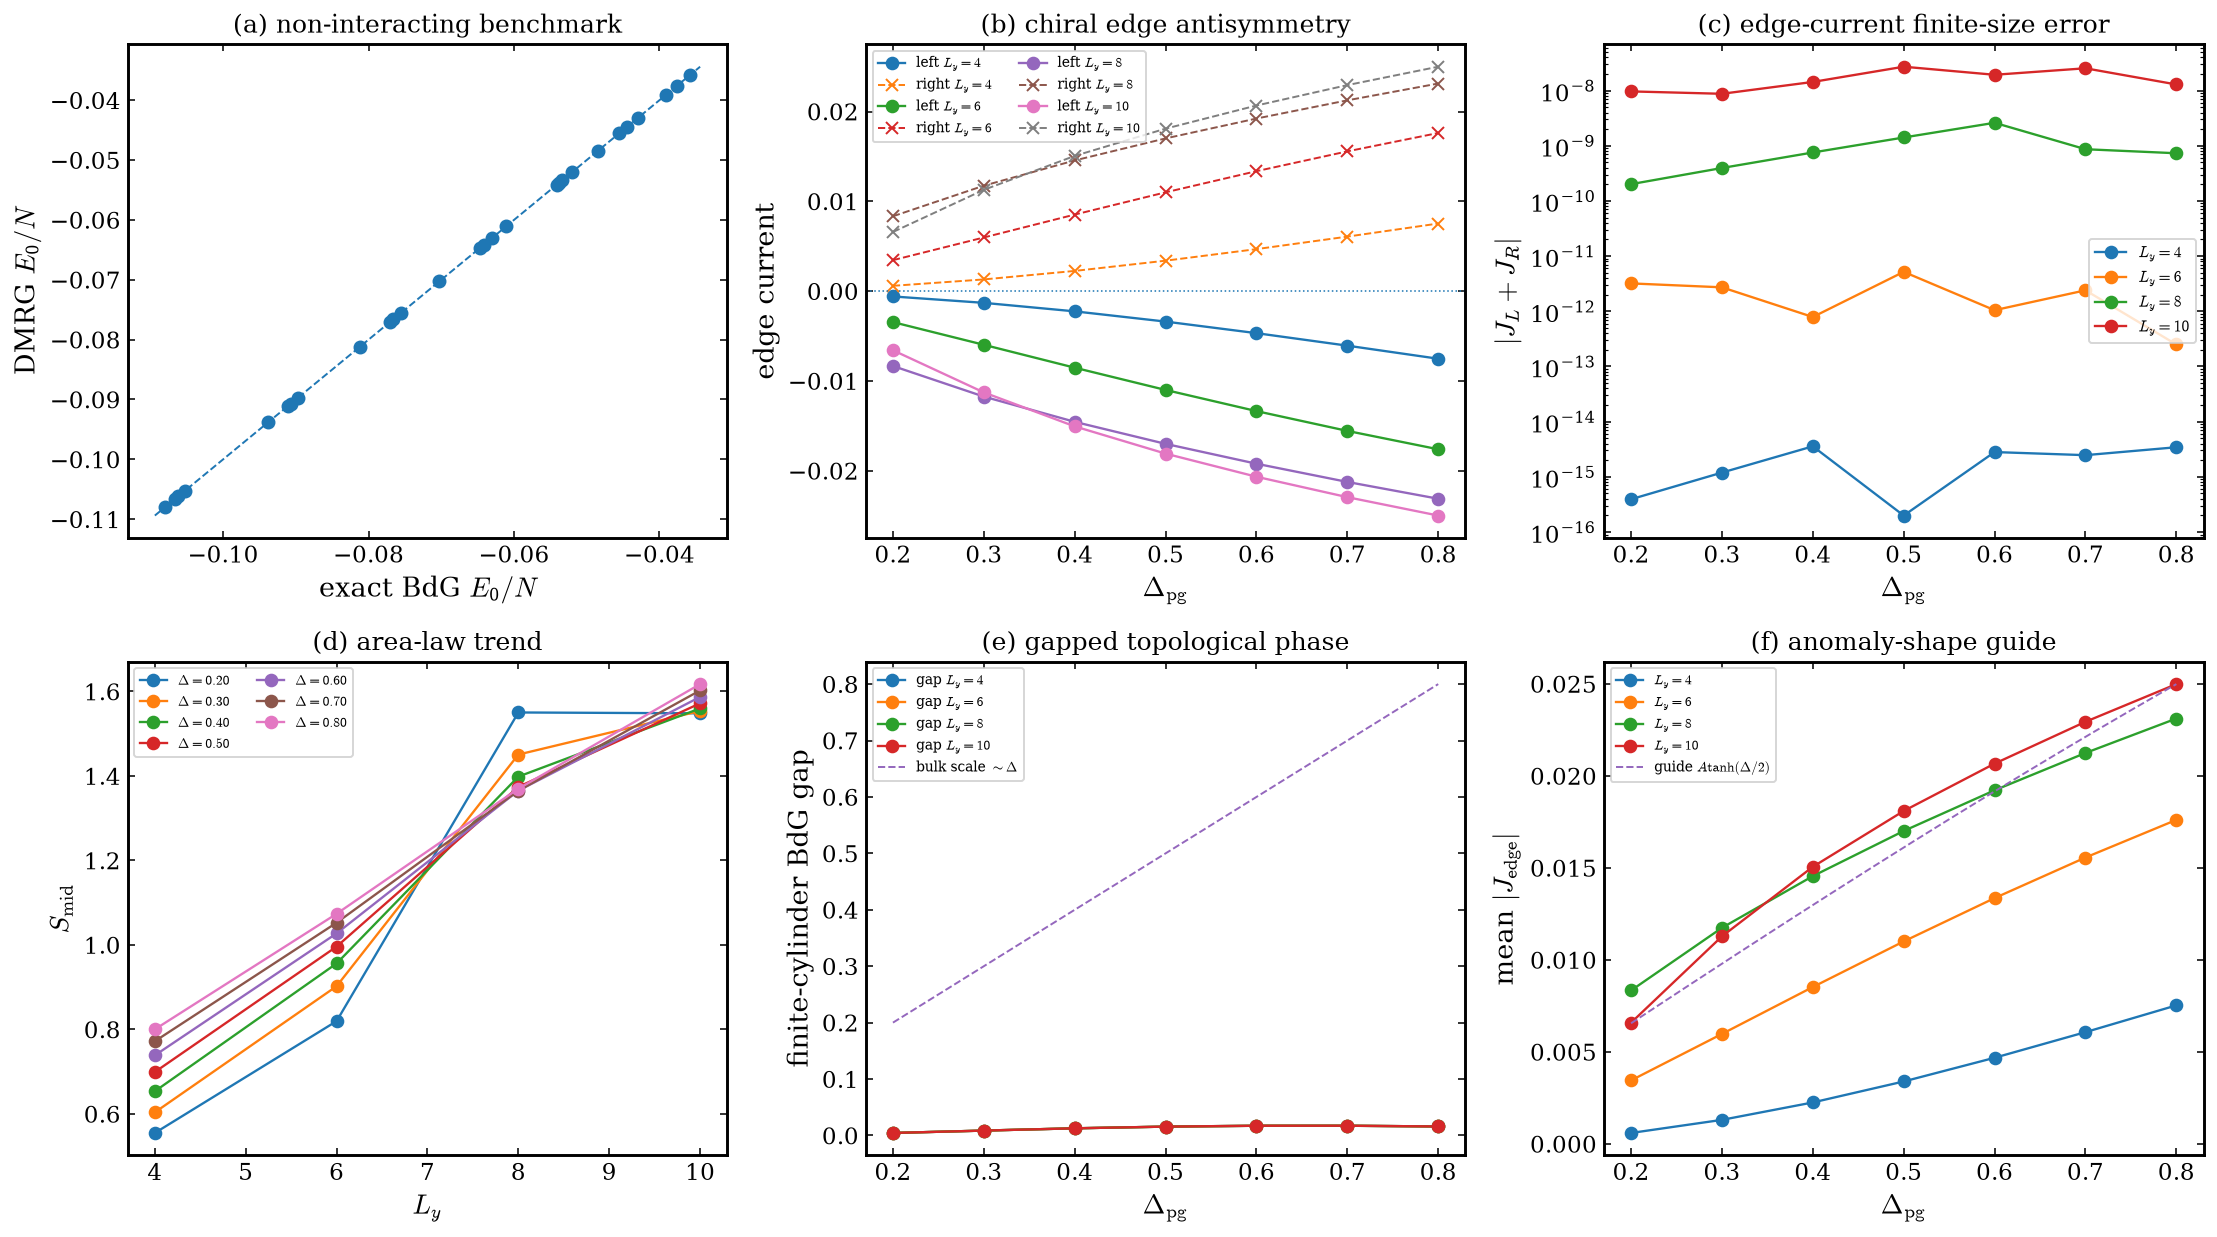

Saved rhg_dmrg_validation_corrected/figures/rhg_dmrg_validation_summary.png
Saved rhg_dmrg_validation_corrected/figures/rhg_dmrg_validation_summary.pdf


In [10]:
if not CSV_PATH.exists():
    print("No master CSV found yet. Run the DMRG scan first, or set RUN_DMRG=True in a TeNPy environment.")
else:
    df = pd.read_csv(CSV_PATH).sort_values(["Ly", "Delta_pg"]).reset_index(drop=True)
    print(df.head())

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    Ly_vals = sorted(df["Ly"].unique())
    Delta_vals = sorted(df["Delta_pg"].unique())

    # (a) DMRG vs exact energy
    ax = axes[0, 0]
    sub = df[np.isfinite(df["E_exact_per_N"])]
    if len(sub):
        ax.scatter(sub["E_exact_per_N"], sub["E_per_N"], s=38)
        lo = min(sub["E_exact_per_N"].min(), sub["E_per_N"].min())
        hi = max(sub["E_exact_per_N"].max(), sub["E_per_N"].max())
        pad = 0.02 * max(1.0e-12, hi - lo)
        ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], "--", lw=1.0)
    ax.set_xlabel(r"exact BdG $E_0/N$")
    ax.set_ylabel(r"DMRG $E_0/N$")
    ax.set_title("(a) non-interacting benchmark")

    # (b) edge currents
    ax = axes[0, 1]
    for Ly_v in Ly_vals:
        s = df[df["Ly"] == Ly_v].sort_values("Delta_pg")
        ax.plot(s["Delta_pg"], s["J_left"], "o-", lw=1.2, label=fr"left $L_y={Ly_v}$")
        ax.plot(s["Delta_pg"], s["J_right"], "x--", lw=1.0, label=fr"right $L_y={Ly_v}$")
    ax.axhline(0.0, lw=0.8, ls=":")
    ax.set_xlabel(r"$\Delta_{\rm pg}$")
    ax.set_ylabel(r"edge current")
    ax.set_title(r"(b) chiral edge antisymmetry")
    ax.legend(fontsize=7, ncol=2)

    # (c) antisymmetry error
    ax = axes[0, 2]
    for Ly_v in Ly_vals:
        s = df[df["Ly"] == Ly_v].sort_values("Delta_pg")
        ax.semilogy(s["Delta_pg"], np.maximum(s["J_antisymmetry"], 1.0e-16), "o-", lw=1.2, label=fr"$L_y={Ly_v}$")
    ax.set_xlabel(r"$\Delta_{\rm pg}$")
    ax.set_ylabel(r"$|J_L+J_R|$")
    ax.set_title("(c) edge-current finite-size error")
    ax.legend(fontsize=8)

    # (d) entanglement entropy vs Ly
    ax = axes[1, 0]
    for D in Delta_vals:
        s = df[np.isclose(df["Delta_pg"], D)].sort_values("Ly")
        ax.plot(s["Ly"], s["S_mid"], "o-", lw=1.2, label=fr"$\Delta={D:.2f}$")
    ax.set_xlabel(r"$L_y$")
    ax.set_ylabel(r"$S_{\rm mid}$")
    ax.set_title("(d) area-law trend")
    if len(Delta_vals) <= 8:
        ax.legend(fontsize=7, ncol=2)

    # (e) exact gap and expected xi=vF/Delta
    ax = axes[1, 1]
    vF = 2.0 * np.sqrt(float(cfg["t"]) * float(cfg["mu"]))
    for Ly_v in Ly_vals:
        s = df[df["Ly"] == Ly_v].sort_values("Delta_pg")
        ax.plot(s["Delta_pg"], s["bdg_gap_exact"], "o-", lw=1.2, label=fr"gap $L_y={Ly_v}$")
    Dfine = np.linspace(max(1.0e-6, min(Delta_vals)), max(Delta_vals), 200)
    ax.plot(Dfine, Dfine, "--", lw=1.0, label=r"bulk scale $\sim\Delta$")
    ax.set_xlabel(r"$\Delta_{\rm pg}$")
    ax.set_ylabel("finite-cylinder BdG gap")
    ax.set_title(r"(e) gapped topological phase")
    ax.legend(fontsize=7)

    # (f) edge current vs tanh envelope; amplitude is non-universal, shape is a guide
    ax = axes[1, 2]
    for Ly_v in Ly_vals:
        s = df[df["Ly"] == Ly_v].sort_values("Delta_pg")
        ax.plot(s["Delta_pg"], np.abs(s["J_edge_abs_mean"]), "o-", lw=1.2, label=fr"$L_y={Ly_v}$")
    finite_J = df["J_edge_abs_mean"].replace([np.inf, -np.inf], np.nan).dropna().abs()
    if len(finite_J):
        scale = float(finite_J.max()) / max(np.tanh(max(Delta_vals) / 2.0), 1.0e-12)
        ax.plot(Dfine, scale * np.tanh(Dfine / 2.0), "--", lw=1.0, label=r"guide $A\tanh(\Delta/2)$")
    ax.set_xlabel(r"$\Delta_{\rm pg}$")
    ax.set_ylabel(r"mean $|J_{\rm edge}|$")
    ax.set_title("(f) anomaly-shape guide")
    ax.legend(fontsize=7)

    fig.tight_layout()
    fig_png = FIG_DIR / "rhg_dmrg_validation_summary.png"
    fig_pdf = FIG_DIR / "rhg_dmrg_validation_summary.pdf"
    fig.savefig(fig_png, dpi=300)
    fig.savefig(fig_pdf, dpi=300)
    plt.show()
    print(f"Saved {fig_png}")
    print(f"Saved {fig_pdf}")

## 7. Entanglement spectrum from saved pickle archives

This figure uses the archived Schmidt values and does not require loading the MPS HDF5 file.

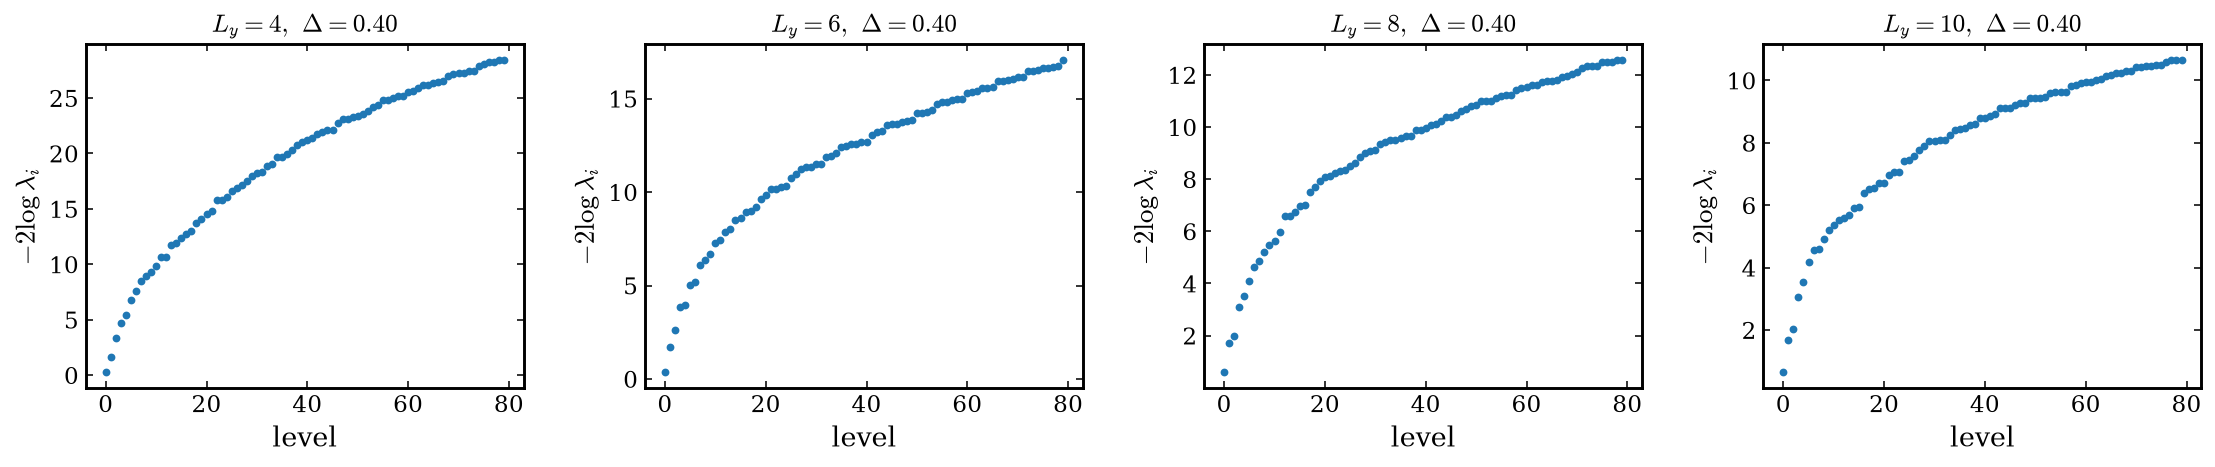

Saved rhg_dmrg_validation_corrected/figures/rhg_entanglement_spectrum.png


In [11]:
archive_files = sorted(PKL_DIR.glob("Lx*_Ly*_D*.pkl"))
if not archive_files:
    print("No pickle archives found yet.")
else:
    # choose the Delta closest to 0.40, if present
    target_D = 0.40
    chosen = []
    for Ly_v in sorted(cfg["Ly_values"]):
        candidates = sorted(PKL_DIR.glob(f"Lx{cfg['Lx_values'][0]}_Ly{Ly_v}_D*.pkl"))
        if not candidates:
            continue
        def dist(path):
            s = path.stem.split("_D")[-1]
            return abs(float(s) - target_D)
        chosen.append(min(candidates, key=dist))

    ncols = min(4, max(1, len(chosen)))
    fig, axes = plt.subplots(1, ncols, figsize=(4*ncols, 3.5), squeeze=False)
    for ax, path in zip(axes[0], chosen[:ncols]):
        with path.open("rb") as f:
            arch = pickle.load(f)
        row = arch["row"]
        es = arch.get("entanglement", {}).get("entanglement_spectrum_mid", [])
        if len(es):
            n = min(80, len(es))
            ax.plot(np.arange(n), es[:n], "o", ms=3)
        ax.set_title(fr"$L_y={row['Ly']},\ \Delta={row['Delta_pg']:.2f}$")
        ax.set_xlabel("level")
        ax.set_ylabel(r"$-2\log \lambda_i$")
    fig.tight_layout()
    fig_path = FIG_DIR / "rhg_entanglement_spectrum.png"
    fig.savefig(fig_path, dpi=300)
    plt.show()
    print(f"Saved {fig_path}")

## 8. Optional: reload an HDF5 MPS checkpoint

This cell demonstrates the intended checkpoint workflow.  It is optional and is not needed for the production summary plots.

In [12]:
def tenpy_load_object_from_group(h5file, group_name):
    """Best-effort TeNPy HDF5 load wrapper across API versions."""
    if hdf5_io is None:
        raise RuntimeError("tenpy.tools.hdf5_io unavailable")
    errors = []
    for args in [(h5file, group_name), (h5file[group_name],)]:
        try:
            return hdf5_io.load_from_hdf5(*args)
        except Exception as exc:
            errors.append(repr(exc))
    raise RuntimeError("No compatible hdf5_io.load_from_hdf5 call succeeded: " + " | ".join(errors))


if HAS_TENPY and HAS_H5PY:
    h5_files = sorted(MPS_DIR.glob("*.h5"))
    if h5_files:
        sample = h5_files[0]
        print(f"Trying to inspect {sample}")
        with h5py.File(sample, "r") as f:
            print("Attributes:", dict(f.attrs))
            print("Top-level keys:", list(f.keys()))
            # Uncomment to actually load the MPS object:
            # psi_loaded = tenpy_load_object_from_group(f, "/psi")
            # print(psi_loaded)
    else:
        print("No HDF5 MPS files found yet.")
else:
    print("TeNPy/h5py unavailable; cannot reload HDF5 MPS checkpoints in this kernel.")

Trying to inspect rhg_dmrg_validation_corrected/mps_hdf5/Lx8_Ly10_D0.200.h5
Attributes: {'created_at': '2026-07-10T00:54:44.822258', 'metadata_json': '{"C_BdG": 1.0000000000000027, "C_integer_error": 2.6645352591003757e-15, "Delta_pg": 0.2, "E_error": 7.217242630463971e-05, "E_error_per_N": 9.021553288079964e-07, "E_exact": -3.128734621864936, "E_exact_per_N": -0.0391091827733117, "E_per_N": -0.039108280617982896, "J_antisymmetry": 9.651239515906518e-09, "J_edge_abs_mean": 0.006584924175141194, "J_left": -0.006584919349521436, "J_left_std": 4.5305706526972047e-08, "J_right": 0.006584929000760952, "J_right_std": 3.801706226429019e-08, "Lx": 8, "Ly": 10, "N": 80, "S_max": 2.003047144434056, "S_mid": 1.5482145667642842, "V_nn": 0.0, "bdg_gap_exact": 0.004434464765062227, "chi_max_reached": 512, "chirality": 1, "energy": -3.1286624494386315, "final_delta_E": -1.0112629755809621e-07, "final_max_trunc_err": 7.855247798097527e-08, "max_plaquette_flux": 0.06720599206678823, "mu": 1.0, "n_mean"

## Interpretation checklist for the RHG draft

A successful production run should show:

* `C_BdG` locked to `+1` for the chosen chirality and `mu=1`.
* DMRG energy matching the exact quadratic BdG energy for `V_nn=0` within the truncation accuracy.
* Opposite edge currents, quantified by small `J_antisymmetry`.
* finite entanglement entropy with an area-law trend as `Ly` is increased.
* no evidence for algebraic finite-size correction in the gapped regime; residual deviations should be analyzed with exponential envelopes rather than forced monotone fits.

For interacting robustness tests, set `V_nn` nonzero only after reproducing the non-interacting benchmark.  Then drop the exact-energy comparison from the acceptance criteria and use convergence, parity sector stability, edge-current antisymmetry, and entanglement profiles instead.

In [13]:
1

1